# 06 · Final pipeline

Covers the *Your Pipeline* checkpoint. The assignment asks for two parts graded separately, so their effects are
measured separately before they are combined:

| part | what changes | what stays fixed |
|---|---|---|
| **A. Inference strategy** | how the frames are shown to the model: horizontal-flip TTA and 2 × 2 overlapping tiles (the slicing idea of SAHI) | the model: RT-DETR R2, the best single model on validation |
| **B. Model change** | which models predict: a Weighted Boxes Fusion (WBF) ensemble of the four detector families | the inference of each model, as in its own notebook |

Every number comes from the same evaluator on the same 2 846 validation frames as notebooks 02–05.
Choices (which views, which models, WBF settings) are made on validation; the final validation score is therefore a
slightly optimistic estimate, and the public leaderboard is only a check.

**Inputs:** the saved predictions of every model (`val_preds*.csv.gz`, `test_preds_*.csv.gz`) and the `results_*.json` logs,
anywhere inside `WORK_DIR` (they are searched for by name). Part A also needs the R2 weights and a GPU (~1 h for val + test);
Part B runs on CPU.

## 1. Setup

In [ ]:
# --- Environment detection and paths (same as notebooks 01-05) -------------------------
import os, sys, glob, subprocess
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/input")
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"   # Colab only: used to download the data

def find_repo():
    """Folder that contains the vdet/ package."""
    if IN_COLAB:  # anywhere on Google Drive (unzipping often adds an extra visdrone-det/ level)
        for depth in range(0, 4):
            hits = sorted(glob.glob("/content/drive/MyDrive/" + "*/" * depth + "vdet/__init__.py"))
            if hits:
                return os.path.dirname(os.path.dirname(hits[0]))
        raise FileNotFoundError("vdet/ not found on Google Drive: upload the visdrone-det folder to MyDrive")
    if IN_KAGGLE:
        for depth in range(1, 6):
            hits = glob.glob("/kaggle/input/" + "*/" * depth + "vdet/__init__.py")
            if hits:
                return os.path.dirname(os.path.dirname(hits[0]))
        raise FileNotFoundError("vdet not found: add the code dataset via '+ Add Input'")
    return os.path.abspath("..")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("VDET_WORK", "/content/drive/MyDrive/visdrone-work")  # results survive disconnects
    if not os.path.exists("/content/data/train"):
        # Kaggle API token, never written into the notebook (it goes to GitHub):
        # Colab sidebar -> key icon (Secrets) -> name KAGGLE_API_TOKEN, value KGAT_..., notebook access ON.
        # Fallback: a legacy kaggle.json in the MyDrive root.
        from google.colab import userdata
        try:
            os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        except Exception:
            !mkdir -p /root/.kaggle && cp /content/drive/MyDrive/kaggle.json /root/.kaggle/ && chmod 600 /root/.kaggle/kaggle.json
        !pip -q install -U kaggle
        !kaggle competitions download -c {COMPETITION} -p /content -q
        !unzip -q -o /content/{COMPETITION}.zip -d /content/data && rm /content/{COMPETITION}.zip

# Ultralytics prints the model summary and a progress bar per epoch; keep the notebook output short.
# Per-epoch numbers are still saved to runs_yolo/<exp>/results.csv and plotted in section 4.
os.environ["YOLO_VERBOSE"] = "False"

for pkg, mod in [("pycocotools", "pycocotools"), ("ultralytics", "ultralytics"), ("ensemble-boxes", "ensemble_boxes")]:
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

REPO_DIR = find_repo()
sys.path.insert(0, REPO_DIR)
print("repo:", REPO_DIR)

Mounted at /content/drive
repo: /content/drive/MyDrive/visdrone-det


In [ ]:
# --- Imports and configuration -------------------------------------------------------
import json, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from ultralytics import YOLO, RTDETR

from vdet import CLASSES
from vdet import data as D, evaluate as E, submission as S, ultra as U, ensemble as ENS
from vdet.paths import find_data_root, default_work_dir
# ensemble-boxes warns for every degenerate box it skips; the skip is correct, the messages are noise
warnings.filterwarnings("ignore", message="Zero area box")

SMOKE = False        # True: a few frames, to test the pipeline. False: the real run.
PART_A = True       # needs a GPU and the RT-DETR R2 weights; False = skip straight to the ensemble

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
DATA_ROOT = find_data_root()
WORK_DIR = default_work_dir()
OUT_DIR = WORK_DIR / ("pipeline_smoke" if SMOKE else "pipeline"); OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = WORK_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

def find(rel):
    """A file anywhere under WORK_DIR: the exact relative path, else the same tail of folders, else the name."""
    p = WORK_DIR / rel
    if p.exists():
        return p
    name, tail = Path(rel).name, Path(rel).parts
    hits = [h for h in WORK_DIR.rglob(name) if "smoke" not in str(h)]
    for k in range(len(tail), 1, -1):                 # same file name with (part of) the same folders
        exact = [h for h in hits if h.parts[-k:] == tail[-k:]]
        if exact:
            return exact[0]
    if len(hits) == 1 and len(tail) == 1:             # a unique name needs no folders
        return hits[0]
    if hits:                                          # e.g. several val_preds.csv.gz: never guess which model
        raise FileNotFoundError(f"{rel}: found {len(hits)} files named {name} but none inside {'/'.join(tail[:-1])}/ "
                                f"-> put it in WORK_DIR/{rel}")
    raise FileNotFoundError(f"{rel} not found under {WORK_DIR}: copy it there (see the notebook intro)")

# The best configuration of every detector family (chosen in its own notebook on validation)
MODELS = {
    "RT-DETR R2":      dict(val="runs_rtdetr/R2/val_preds.csv.gz",  test="test_preds_rtdetr_R2.csv.gz", log="results_rtdetr.json", run="R2"),
    "Faster R-CNN F0": dict(val="runs_frcnn/F0/val_preds_2.csv.gz", test="test_preds_frcnn_F0.csv.gz",  log="results_frcnn.json",  run="F0 | 500 det, score 0.001, 3000 prop."),
    "YOLOv8s E1":      dict(val="runs_yolo/E1/val_preds.csv.gz",    test="test_preds_yolo_E1.csv.gz",   log="results_yolo.json",   run="E1"),
    "RetinaNet N0":    dict(val="runs_retina/N0/val_preds_1.csv.gz", test="test_preds_retina_N0.csv.gz", log="results_retina.json", run="N0 | 500 det, score 0.001"),
}
TTA_WEIGHTS = "runs_rtdetr/R2/weights/last.pt"   # the model Part A works on
# Public leaderboard scores of the single-model submissions (fill in from Kaggle; None = not submitted)
LB = {"RT-DETR R2": 0.25, "Faster R-CNN F0": 0.2417, "YOLOv8s E1": 0.2162, "RetinaNet N0": None}
print("work:", WORK_DIR, "| device:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")

work: /content/drive/MyDrive/visdrone-work | device: Tesla T4


In [ ]:
# --- Data: validation ground truth and image sizes ------------------------------------
tv = D.load_train_val(DATA_ROOT)
val_keys = tv.images[tv.images.split == "val"].key
if SMOKE:
    val_keys = D.subsample_frames(tv.images[tv.images.split == "val"], 50).key
val = tv.subset(val_keys)
test = D.load_test_images(DATA_ROOT)
if SMOKE:
    test = test.groupby("clip").head(2)
sizes = pd.concat([val.images[["key", "width", "height"]], test[["key", "width", "height"]]], ignore_index=True)
ev = E.DetectionEvaluator(val)
keep = lambda p, keys: p[p.key.isin(set(keys))].reset_index(drop=True)
cols = ["mAP", "AP50", "AP75", "AP_tiny", "AP_small", "AP_medium", "AP_large", "AR500"]

# Every evaluation is stored in OUT_DIR/evals.json as soon as it is computed. After a disconnect, Run all
# reads the stored metrics and skips both the merge and the evaluation (each costs minutes on CPU).
EVAL_CACHE = OUT_DIR / "evals.json"
def _cache():
    return json.loads(EVAL_CACHE.read_text()) if EVAL_CACHE.exists() else {}
def cached_eval(name, make_preds, per_class=False):
    """Metrics of the predictions `make_preds()` builds; computed once, then read from disk."""
    cache = _cache()
    if name in cache:
        return cache[name]
    m = {k: float(v) for k, v in ev.evaluate(make_preds(), per_class=per_class).items()}
    cache = _cache(); cache[name] = m
    EVAL_CACHE.write_text(json.dumps(cache, indent=1))
    return m
def seed_cache(table_csv):
    """Metrics already shown in a table saved by an earlier run (before this cache existed)."""
    if not table_csv.exists():
        return
    cache = _cache()
    for name, r in pd.read_csv(table_csv, index_col=0).iterrows():
        cache.setdefault(name, {c: float(r[c]) / 100 for c in cols if c in r})
    EVAL_CACHE.write_text(json.dumps(cache, indent=1))
print("val frames:", len(val.images), "| test frames:", len(test))

val frames: 2846 | test frames: 3811


## 2. All models side by side
The best configuration of each family from notebooks 02–05, re-evaluated here from its saved validation predictions
(so every row comes from the same evaluator run), next to its public leaderboard score.

In [ ]:
val_preds, rows = {}, {}
for name, m in MODELS.items():
    try:
        val_preds[name] = keep(pd.read_csv(find(m["val"])), val.images.key)
    except FileNotFoundError as e:
        print("skipped:", e); continue
    r = dict(cached_eval(f"model: {name}", lambda name=name: val_preds[name], per_class=True))
    log = json.loads(find(m["log"]).read_text()) if not SMOKE else {}
    r["ms_per_img"] = log.get(m["run"], {}).get("metrics", {}).get("ms_per_img", np.nan)
    r["public LB"] = LB.get(name)
    rows[name] = r
summary = pd.DataFrame(rows).T
summary = summary[cols].astype(float).mul(100).round(1).join(summary[["ms_per_img", "public LB"]]).sort_values("mAP", ascending=False)
summary.to_csv(OUT_DIR / "summary_models.csv")
summary

skipped: runs_retina/N0/val_preds_1.csv.gz not found under /content/drive/MyDrive/visdrone-work: copy it there (see the notebook intro)


,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR500,ms_per_img,public LB
RT-DETR R2,23.4,46.8,20.4,1.2,10.8,22.4,39.1,39.3,115.7,0.2500
Faster R-CNN F0,19.8,41.8,16.5,1.9,9.7,18.0,36.1,38.4,150.8,0.2417
YOLOv8s E1,19.8,39.3,17.6,1.6,12.7,18.9,31.6,32.3,55.2,0.2162


In [ ]:
pc = pd.DataFrame(rows).T[[f"AP_{c}" for c in CLASSES]].astype(float).mul(100).round(1)
pc.columns = CLASSES
pc

,person,bicycle,car,van,truck,tricycle,bus,motor
RT-DETR R2,29.0,21.6,42.3,25.6,30.0,23.2,3.1,12.7
Faster R-CNN F0,25.8,17.4,38.0,22.1,26.5,18.2,0.4,9.9
YOLOv8s E1,27.6,20.2,38.6,15.4,21.0,21.7,2.0,12.3


> **Observation.** RT-DETR R2 is the strongest single model (23.4 mAP), best on medium and large objects (AP_large 39.1).
> Faster R-CNN and YOLO tie at 19.8 mAP but are strong in different places: YOLO on small objects (AP_small 12.7, the
> best of all models), Faster R-CNN on recall (AR500 38.4 vs 32.3) and large objects. RT-DETR leads on almost every
> class; YOLO is close on bicycle and motor but weak on van (15.4). These differences are what an ensemble can use.
> RetinaNet N0 is missing in this run (its validation predictions were not on this Drive), so it is not in the
> ensemble; with 16.7 mAP it would most likely add little. The public LB of R2 is 0.2583 (rounded to 0.25 in the table).

## 3. Part A · inference strategy (model fixed: RT-DETR R2)
Each validation frame is shown to the same model in up to three ways, each view's boxes mapped back to the original frame:
* **full** – the whole frame at 1280 px, as in notebook 05;
* **flip** – the mirrored frame (test-time augmentation: the model's errors on a mirrored scene are partly independent);
* **tiles** – 2 × 2 crops overlapping by 20 %, each resized to 1280 px, so every object appears ~1.8 × larger.

The views are merged with WBF. RT-DETR returns at most 300 boxes per view, so merging views also lifts that cap.

In [ ]:
def views_cached(images, split):
    """Predict all views once and cache them, so a disconnect does not cost the GPU time again."""
    files = {v: OUT_DIR / f"{split}_R2_{v}.csv.gz" for v in ("full", "flip", "tiles")}
    if all(f.exists() for f in files.values()):
        return {v: pd.read_csv(f) for v, f in files.items()}
    w = find(TTA_WEIGHTS)
    model = (RTDETR if "rtdetr" in str(w) else YOLO)(str(w))
    out, sec = U.predict_views(model, images, views=("full", "flip", "tiles"), imgsz=320 if SMOKE else 1280,
                               half=DEVICE == 0, desc=f"{split} views")
    for v, p in out.items():
        p.to_csv(files[v], index=False)
    print(f"{split}: {sec:.2f} s per frame for 6 forward passes (full, flip, 4 tiles)")
    return out

_vv = {}
def val_views():
    if not _vv:
        _vv.update(views_cached(val.images, "val"))
    return _vv

def merge_views(view_names, conf_type, split_views):
    """One view as is, or several views fused with WBF."""
    v = split_views()
    if len(view_names) == 1:
        return v[view_names[0]]
    return ENS.wbf([v[n] for n in view_names], sizes, iou_thr=0.6, conf_type=conf_type, desc=" + ".join(view_names))

if PART_A:
    seed_cache(OUT_DIR / "part_a.csv")               # results of a run made before the cache existed
    A_CANDIDATES = {"full": ["full"], "full + flip": ["full", "flip"], "full + tiles": ["full", "tiles"],
                    "full + flip + tiles": ["full", "flip", "tiles"]}
    part_a, spec_a = {}, {}
    for name, vs in A_CANDIDATES.items():
        for conf_type in (["avg"] if len(vs) == 1 else ["avg", "max"]):
            label = name if len(vs) == 1 else f"{name} (WBF {conf_type})"
            spec_a[label] = (vs, conf_type)
            part_a[label] = cached_eval(label, lambda vs=vs, ct=conf_type: merge_views(vs, ct, val_views))
    tab_a = pd.DataFrame(part_a).T[cols].astype(float).mul(100).round(1).sort_values("mAP", ascending=False)
    tab_a.to_csv(OUT_DIR / "part_a.csv")
    display(tab_a)

,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR500
full + flip + tiles (WBF max),25.1,49.7,21.9,0.7,13.4,23.7,40.9,43.8
full + flip (WBF max),25.0,49.5,21.7,1.6,12.3,23.3,41.1,40.0
full + flip + tiles (WBF avg),24.9,50.0,21.2,1.1,12.7,23.6,41.2,43.8
full + tiles (WBF max),24.1,48.3,20.6,0.6,13.0,23.4,39.1,42.8
full + flip (WBF avg),24.0,48.2,20.5,1.2,11.3,22.5,40.4,40.0
full + tiles (WBF avg),23.7,47.9,20.1,1.1,11.7,22.9,39.9,42.8
full,23.4,46.8,20.5,1.2,10.8,22.4,39.1,39.3


> **Observation.** Every extra view helps. The best merge, full + flip + tiles with WBF "max", gives +1.7 mAP (23.4 → 25.1).
> Flip alone gives +1.6 and helps all sizes. Tiles alone give only +0.7, but they raise AP_small most (10.8 → 13.0) and
> AR500 (39.3 → 42.8): objects in a tile are ~1.8× larger, and merging views lifts RT-DETR's limit of 300 boxes per view.
> "max" beats "avg" in every combination: with "avg" a box found in only one view (e.g. a small object visible only in a
> tile) has its score divided by the number of views. AP_tiny drops (1.2 → 0.7), but it covers only ~0.4% of val
> objects and is noise. Cost: 6 forward passes, 0.46 s per frame instead of one pass.

## 4. Part B · model change: a WBF ensemble of the detector families
The inference of each model stays as in its own notebook; only the set of models changes. First every subset that
adds one family at a time (strongest first), then, for the best subset, the WBF IoU threshold and model weights.
Weights proportional to each model's validation mAP are the only learned choice; there are few of them, and the
search is kept small to limit fitting to the validation set.

In [ ]:
order = summary.index.tolist()                      # strongest model first
part_b, merged_b = {}, {}
for k in range(1, len(order) + 1):
    members = order[:k]
    name = " + ".join(members)
    merged_b[name] = (members, None, 0.6)
    part_b[name] = rows[members[0]] if k == 1 else cached_eval(
        name, lambda members=members: ENS.wbf([val_preds[m] for m in members], sizes, iou_thr=0.6, desc=f"{len(members)} models"))
tab_b = pd.DataFrame(part_b).T[cols].astype(float).mul(100).round(1)
display(tab_b)

,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR500
RT-DETR R2,23.4,46.8,20.4,1.2,10.8,22.4,39.1,39.3
RT-DETR R2 + Faster R-CNN F0,24.1,48.6,20.8,1.8,11.2,22.5,40.9,42.5
RT-DETR R2 + Faster R-CNN F0 + YOLOv8s E1,25.5,50.7,22.4,2.1,13.5,23.9,42.0,43.5


In [ ]:
# Tune the best subset: IoU threshold of the clustering and per-model weights
best_subset = max((n for n in part_b if " + " in n), key=lambda n: part_b[n]["mAP"], default=None)
if best_subset:
    members = merged_b[best_subset][0]
    w_map = [summary.loc[m, "mAP"] for m in members]
    for iou_thr in (0.5, 0.6, 0.7):
        for wname, weights in (("equal", None), ("by val mAP", w_map)):
            name = f"{best_subset} | iou {iou_thr}, weights {wname}"
            merged_b[name] = (members, weights, iou_thr)
            part_b[name] = cached_eval(name, lambda w=weights, t=iou_thr: ENS.wbf(
                [val_preds[m] for m in members], sizes, weights=w, iou_thr=t, desc=f"iou {t}"))
tab_b = pd.DataFrame(part_b).T[cols].astype(float).mul(100).round(1).sort_values("mAP", ascending=False)
tab_b.to_csv(OUT_DIR / "part_b.csv")
tab_b

,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR500
"RT-DETR R2 + Faster R-CNN F0 + YOLOv8s E1 | iou 0.7, weights equal",25.7,50.3,23.0,2.2,13.6,24.0,42.6,43.9
"RT-DETR R2 + Faster R-CNN F0 + YOLOv8s E1 | iou 0.7, weights by val mAP",25.7,50.3,23.0,2.1,13.4,24.1,42.7,43.9
"RT-DETR R2 + Faster R-CNN F0 + YOLOv8s E1 | iou 0.6, weights equal",25.5,50.7,22.4,2.1,13.5,23.9,42.0,43.5
RT-DETR R2 + Faster R-CNN F0 + YOLOv8s E1,25.5,50.7,22.4,2.1,13.5,23.9,42.0,43.5
"RT-DETR R2 + Faster R-CNN F0 + YOLOv8s E1 | iou 0.6, weights by val mAP",25.5,50.7,22.5,2.0,13.4,24.0,42.2,43.6
"RT-DETR R2 + Faster R-CNN F0 + YOLOv8s E1 | iou 0.5, weights by val mAP",25.1,50.4,21.7,1.7,12.9,23.6,41.4,43.2
"RT-DETR R2 + Faster R-CNN F0 + YOLOv8s E1 | iou 0.5, weights equal",25.0,50.4,21.7,1.9,13.1,23.5,41.3,43.2
RT-DETR R2 + Faster R-CNN F0,24.1,48.6,20.8,1.8,11.2,22.5,40.9,42.5
RT-DETR R2,23.4,46.8,20.4,1.2,10.8,22.4,39.1,39.3


> **Observation.** Adding Faster R-CNN to RT-DETR gives +0.7 mAP, adding YOLO another +1.4 (→ 25.5), although YOLO is the weakest of
> the three alone: it brings the best small-object detections (AP_small 11.2 → 13.5). Tuning WBF changes little: IoU 0.7
> is best (25.7) and 0.5 worst (25.0–25.1), because in dense scenes a low threshold merges neighbouring objects into one
> box; equal weights and weights by val mAP differ by less than 0.1. Selected Part B: the three models, IoU 0.7, weights
> by val mAP: 25.7 mAP, +2.3 over the best single model.

## 5. Combining both parts
The best Part A view merge replaces the plain RT-DETR predictions inside the best Part B ensemble. Its effect is
reported on top of the best ensemble, so the three steps (single model → + inference strategy → + ensemble → both)
stay separate.

In [ ]:
BEST_B = max(part_b, key=lambda n: part_b[n]["mAP"])
members_b, weights_b, iou_b = merged_b[BEST_B]
steps = {"single best model (RT-DETR R2)": rows.get("RT-DETR R2")}
if PART_A:
    BEST_A = max(part_a, key=lambda n: part_a[n]["mAP"])
    steps[f"A: {BEST_A}"] = part_a[BEST_A]
steps[f"B: {BEST_B}"] = part_b[BEST_B]
if PART_A and "RT-DETR R2" in members_b and BEST_A != "full":
    def a_plus_b():
        r2 = merge_views(*spec_a[BEST_A], val_views)
        return ENS.wbf([r2 if m == "RT-DETR R2" else val_preds[m] for m in members_b], sizes,
                       weights=weights_b, iou_thr=iou_b, desc="A + B")
    steps["A + B"] = cached_eval(f"A + B: {BEST_A} | {BEST_B}", a_plus_b)
steps = {k: v for k, v in steps.items() if v is not None}
tab_steps = pd.DataFrame(steps).T[cols].astype(float).mul(100).round(1)
tab_steps.to_csv(OUT_DIR / "steps.csv")
FINAL = tab_steps["mAP"].idxmax()
print("final pipeline:", FINAL)
tab_steps

final pipeline: A + B


,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR500
single best model (RT-DETR R2),23.4,46.8,20.4,1.2,10.8,22.4,39.1,39.3
A: full + flip + tiles (WBF max),25.1,49.7,21.9,0.7,13.4,23.7,40.9,43.8
"B: RT-DETR R2 + Faster R-CNN F0 + YOLOv8s E1 | iou 0.7, weights by val mAP",25.7,50.3,23.0,2.1,13.4,24.1,42.7,43.9
A + B,26.7,51.9,24.0,2.6,15.3,24.8,43.5,45.8


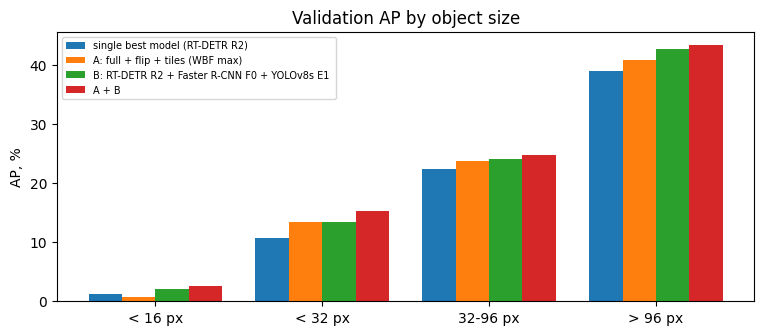

In [ ]:
# mAP by object size along the steps: where does each part help?
fig, ax = plt.subplots(figsize=(9, 3.5))
sz = ["AP_tiny", "AP_small", "AP_medium", "AP_large"]
x = np.arange(len(sz)); wd = 0.8 / len(tab_steps)
for i, (name, r) in enumerate(tab_steps.iterrows()):
    ax.bar(x + i * wd, r[sz].values, wd, label=name[:45])
ax.set_xticks(x + wd * (len(tab_steps) - 1) / 2, ["< 16 px", "< 32 px", "32-96 px", "> 96 px"])
ax.set_ylabel("AP, %"); ax.legend(fontsize=7); ax.set_title("Validation AP by object size")
fig.savefig(FIG_DIR / "pipeline_steps_by_size.png", bbox_inches="tight"); plt.show()

> **Observation.** The two parts add up: A + B reaches 26.7 mAP, +3.3 over RT-DETR alone and +1.0 over B. Both parts help every size
> above 16 px. The largest relative gain is on small objects (AP_small 10.8 → 15.3, +42%); large objects gain +4.4.
> B helps large objects more than A (42.7 vs 40.9), while for small objects both give the same (13.4). The gains are
> only partly additive (1.7 + 2.3 = 4.0 expected, 3.3 measured), because both parts fix some of the same misses.

## 6. Test predictions and the two final submissions
Kaggle lets you select two final submissions; both are chosen here by validation, not by the public score:
1. the final pipeline (best row above);
2. the best Part B ensemble without test-time views (cheaper, and a safeguard if the views overfit validation).

In [ ]:
test_preds = {}
for m in members_b:
    test_preds[m] = keep(pd.read_csv(find(MODELS[m]["test"])), test.key)

def write(name, preds):
    if SMOKE:
        print(f"{name}: {len(preds)} detections (smoke: no file)"); return
    S.write_submission(preds, DATA_ROOT, WORK_DIR / f"submission_{name}.csv")

# Submission 2: the ensemble without test-time views
ens = ENS.wbf([test_preds[m] for m in members_b], sizes, weights=weights_b, iou_thr=iou_b, desc="test ensemble")
write("ensemble", ens)

# Submission 1: the final pipeline
if FINAL.startswith("A + B") or FINAL.startswith("A:"):
    tv_ = views_cached(test, "test")                                 # ~40 min on a T4 for 3 811 frames
    view_names = [v for v in ("full", "flip", "tiles") if v in BEST_A.split(" (")[0].split(" + ")]
    conf_type = "max" if "max" in BEST_A else "avg"
    r2_test = ENS.wbf([tv_[v] for v in view_names], sizes, iou_thr=0.6, conf_type=conf_type, desc="test views")
    if FINAL.startswith("A + B"):
        final = ENS.wbf([r2_test if m == "RT-DETR R2" else test_preds[m] for m in members_b], sizes,
                        weights=weights_b, iou_thr=iou_b, desc="test A + B")
    else:
        final = r2_test
    write("final", final)
else:
    print("final pipeline = the ensemble above")

saved /content/drive/MyDrive/visdrone-work/submission_ensemble.csv: 3811 rows, 1886257 detections, 0 empty rows


test: 0.46 s per frame for 6 forward passes (full, flip, 4 tiles)


saved /content/drive/MyDrive/visdrone-work/submission_final.csv: 3811 rows, 1899970 detections, 0 empty rows


## 7. Summary

The ensemble (Part B) helped slightly more than the inference strategy (Part A): +2.3 vs +1.7 mAP; together +3.3
(23.4 → 26.7). WBF helps because the three detectors make different errors: RT-DETR is best on medium and large
objects, YOLO on small ones, Faster R-CNN has high recall. WBF averages the coordinates of boxes that agree, which
improves localisation (AP75 20.4 → 24.0), and lowers the score of boxes that only one model found. Tiles show every
object ~1.8× larger and lift the limit of 300 boxes per view, so they mainly raise recall and AP on small objects.

**Selected submissions (chosen on validation, not on the public score):**
1. `submission_final.csv` = A + B: RT-DETR R2 with full + flip + tiles views, fused with Faster R-CNN F0 and YOLOv8s E1
   (WBF, IoU 0.7, weights by val mAP): 26.7 val mAP, the best pipeline.
2. `submission_ensemble.csv` = B only, without test-time views: 25.7 val mAP; cheaper, and a safeguard if the view
   settings overfit the validation set.

The views, the ensemble members, the IoU threshold and the weights were all chosen on the same validation frames,
so 26.7 is slightly optimistic. The public leaderboard confirms this: the two submissions score 0.277 (A + B) and
0.278 (B only). The ensemble transferred to the test set (+0.02 over RT-DETR alone, 0.2583), while the extra gain of
the test-time views did not; the 0.001 difference is within leaderboard noise.